# UTS Graf Sains Data
# Rekomendasi dengan Neo4j (RetailRocket)
**Dataset:** [RetailRocket e-commerce dataset](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset) (Roman Zykov)

**Nama:** NANI FITRIA RAMADHANI  

**NIM:** 23031554013

**Kelas:** Graf Sains Data 2023B
| Fold | Mulai | Hingga |
|---|---|---|
| Training (P1) | 2 Mei 2015 | 2 Juli 2015 |
| Testing (P2) | 11 Juli 2015 | 26 Juli 2015 |

**Pertanyaan pendahuluan (checkpoint)**
1. Nama database pada tutorial: `neo4j` (argumen `database_="neo4j"`).
2. Akses database lain dalam 1 instance: parameter `database_="nama_db"` pada `execute_query`, atau `driver.session(database="nama_db")`; di Cypher/Neo4j Browser dengan `:use nama_db`.
3. Jenis graf pertemanan: graf berarah (`KNOWS` punya arah), satu jenis simpul (`Person`), satu jenis relasi, tanpa bobot; bentuk bintang dengan Arthur di pusat.

## Konfigurasi & koneksi

In [2]:
import os, random
import numpy as np, pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from neo4j import GraphDatabase
from sklearn.preprocessing import normalize

URI  = "bolt://localhost:7687"
AUTH = ("neo4j", "password")  # ganti dengan username dan password Neo4j mu
DB   = "neo4j"
DATA_DIR = r"dataset"                 # folder berisi events.csv hasil unzip ecommerce-dataset.zip

TRAIN_START, TRAIN_END = "2015-05-02", "2015-07-02"
TEST_START,  TEST_END  = "2015-07-11", "2015-07-26"
SEED = 42

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j")

Terhubung ke Neo4j


## 2.1 Wrangling dan EDA

### 1. Tentukan 2 periode waktu sebagai filter dari data interaksi.

In [3]:
TRAIN_START, TRAIN_END = "2015-05-02", "2015-07-02"   # Fold training (P1)
TEST_START,  TEST_END  = "2015-07-11", "2015-07-26"   # Fold testing  (P2)

assert pd.Timestamp(TRAIN_END) < pd.Timestamp(TEST_START)

periode = pd.DataFrame({
    "fold":   ["Training (P1)", "Testing (P2)"],
    "mulai":  [TRAIN_START, TEST_START],
    "hingga": [TRAIN_END, TEST_END],
})
periode["durasi_hari"] = (pd.to_datetime(periode["hingga"]) - pd.to_datetime(periode["mulai"])).dt.days + 1
display(periode)

,fold,mulai,hingga,durasi_hari
0,Training (P1),2015-05-02,2015-07-02,62
1,Testing (P2),2015-07-11,2015-07-26,16


### 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [4]:
df = pd.read_csv(os.path.join(DATA_DIR, "events.csv"))
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
print("Total baris:", len(df), "| rentang data:", df.dt.min(), "->", df.dt.max())

def in_range(d, start, end):
    return (d >= pd.Timestamp(start, tz="UTC")) & (d < pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1))

train = df[in_range(df.dt, TRAIN_START, TRAIN_END)].drop(columns="dt")
test  = df[in_range(df.dt, TEST_START,  TEST_END )].drop(columns="dt")

train.to_csv(os.path.join(DATA_DIR, "events_train.csv"), index=False)
test.to_csv(os.path.join(DATA_DIR, "events_test.csv"), index=False)

print("Train:", train.shape, "| visitor:", train.visitorid.nunique(), "| item:", train.itemid.nunique())
print("Test :", test.shape,  "| visitor:", test.visitorid.nunique(),  "| item:", test.itemid.nunique())
print(train.event.value_counts(), "\n", test.event.value_counts())

Total baris: 2756101 | rentang data: 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00
Train: (1243222, 5) | visitor: 627439 | item: 165655
Test : (369601, 5) | visitor: 210215 | item: 89680
event
view           1202807
addtocart        30411
transaction      10004
Name: count, dtype: int64 
 event
view           358089
addtocart        8707
transaction      2805
Name: count, dtype: int64


### Impor fold training ke Neo4j (batch)
Hanya fold training yang dimasukkan ke graf, fold testing dipakai nanti untuk evaluasi (Hit@5, NDCG@5).

In [6]:
RESET = True   # True : menghapus seluruh isi database

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

csv_path = os.path.join(DATA_DIR, "events_train.csv")
batch_size = 5000
total_rows = len(train)
total_chunks = total_rows // batch_size + 1

with driver.session(database=DB) as session:
    if RESET:
        session.run("MATCH (n) DETACH DELETE n")
    create_constraints(session)
    for chunk in tqdm(pd.read_csv(csv_path, chunksize=batch_size), total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        session.execute_write(import_batch, chunk.to_dict(orient="records"))
print("Proses impor selesai")

Mengimpor Batch Data: 100%|██████████| 249/249 [02:25<00:00,  1.72it/s]

Proses impor selesai


In [7]:
with driver.session(database=DB) as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS label, count(n) AS jumlah
    """)

    for record in result:
        print(record["label"], record["jumlah"])

    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
    """)

    for record in result:
        print(record["jenis_relasi"], record["jumlah"])

['Visitor'] 627439
['Item'] 165655
ADDED_TO_CART 30411
BOUGHT 10004
VIEWED 1202807


### 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan! 

**Penjelasan Cypher:**
1. `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah`
   - `MATCH (n)` mencocokkan semua simpul di database (tanpa label dan filter).
   - `labels(n)` mengembalikan daftar label sebuah simpul, dan `[0]` mengambil label pertama (di sini `Visitor` atau `Item`).
   - `count(n)` menghitung simpul. Karena `labels(n)[0]` adalah kolom non-agregat, Cypher otomatis mengelompokkan (group by) berdasarkan jenis simpul, sehingga hasilnya satu baris per jenis simpul.
2. `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah`
   - `()-[r]->()` mencocokkan semua relasi berarah di antara dua simpul apa pun.
   - `type(r)` mengembalikan nama jenis relasi dan `count(r)` menghitung jumlahnya per jenis.

**Python API:** `driver.session(database=DB)` membuka sesi ke Neo4j lewat protokol Bolt, `s.run(query)` mengirim query Cypher, dan `.data()` mengubah hasilnya menjadi list of dictionary yang kemudian dijadikan `DataFrame` pandas.

**Jenis dan jumlah simpul**
Subgraph yang dibentuk dari fold training (2 Mei - 2 Juli 2015) memiliki dua jenis simpul, yaitu `Visitor` (627.439) dan `Item` (165.655), dengan total 793.094 simpul. Simpul `Visitor` mendominasi sekitar 79% dari seluruh simpul, dengan rasio sekitar 3,8 visitor untuk setiap item.

Terdapat tiga jenis relasi berarah dari `Visitor` ke `Item`, dengan total 1.243.222 relasi. Relasi `VIEWED` sangat dominan (96,75%), sedangkan `ADDED_TO_CART` hanya 2,45% dan `BOUGHT` 0,80%. Ini sesuai pola e-commerce, yaitu banyak pengunjung melihat produk tetapi hanya sebagian kecil yang memasukkan ke keranjang atau membeli. Secara kasar, rasio `ADDED_TO_CART` terhadap `VIEWED` adalah 2,5% dan `BOUGHT` terhadap `ADDED_TO_CART` sekitar 32,9%.

Graf ini bersifat **bipartit** (relasi hanya menghubungkan `Visitor` dengan `Item`, tidak ada relasi antar sesama visitor atau sesama item). Rata-rata satu visitor memiliki sekitar 1,98 relasi dan satu item memiliki sekitar 7,50 relasi. Kepadatan graf sangat rendah, yaitu sekitar 1,20 × 10⁻⁵ (1.243.222 relasi dibanding 627.439 × 165.655 kemungkinan pasangan), sehingga graf ini sangat sparse. Nilai ini merupakan batas atas, karena satu pasangan visitor-item bisa memiliki beberapa relasi.

In [8]:
with driver.session(database=DB) as s:
    nodes = s.run("MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah").data()
    rels  = s.run("""
        MATCH ()-[r]->()
        WHERE type(r) <> 'SIMILAR_TO'
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jumlah DESC
    """).data()

df_nodes = pd.DataFrame(nodes).sort_values("jumlah", ascending=False).reset_index(drop=True)
df_rels  = pd.DataFrame(rels)

df_nodes["persentase"] = (df_nodes["jumlah"] / df_nodes["jumlah"].sum() * 100).round(2)
df_rels["persentase"]  = (df_rels["jumlah"]  / df_rels["jumlah"].sum()  * 100).round(2)

display(df_nodes); print("Total simpul :", df_nodes["jumlah"].sum())
display(df_rels);  print("Total relasi :", df_rels["jumlah"].sum())

n = dict(zip(df_nodes.jenis_simpul, df_nodes.jumlah))
r = dict(zip(df_rels.jenis_relasi, df_rels.jumlah))
n_vis, n_item, n_rel = n["Visitor"], n["Item"], sum(r.values())
print(f"Rasio Visitor : Item                = {n_vis / n_item:.2f} : 1")
print(f"Rata-rata relasi per Visitor        = {n_rel / n_vis:.2f}")
print(f"Rata-rata relasi per Item           = {n_rel / n_item:.2f}")
print(f"ADDED_TO_CART / VIEWED              = {r['ADDED_TO_CART'] / r['VIEWED']:.2%}")
print(f"BOUGHT / ADDED_TO_CART              = {r['BOUGHT'] / r['ADDED_TO_CART']:.2%}")
print(f"Kepadatan (relasi / (Visitor x Item)) = {n_rel / (n_vis * n_item):.2e}")

,jenis_simpul,jumlah,persentase
0,Visitor,627439,79.11
1,Item,165655,20.89


Total simpul : 793094


,jenis_relasi,jumlah,persentase
0,VIEWED,1202807,96.75
1,ADDED_TO_CART,30411,2.45
2,BOUGHT,10004,0.80


Total relasi : 1243222
Rasio Visitor : Item                = 3.79 : 1
Rata-rata relasi per Visitor        = 1.98
Rata-rata relasi per Item           = 7.50
ADDED_TO_CART / VIEWED              = 2.53%
BOUGHT / ADDED_TO_CART              = 32.90%
Kepadatan (relasi / (Visitor x Item)) = 1.20e-05


### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Graf asli adalah **bipartit** (Visitor - Item). Matriks interaksi biner `X` (user x item):
- VSM **User**: tiap user = baris `X` (vektor berdimensi jumlah item).
- VSM **Item**: tiap item = kolom `X` (= baris `X.T`, vektor berdimensi jumlah user).

In [9]:
with driver.session(database=DB) as s:
    pairs = pd.DataFrame(s.run(
        "MATCH (v:Visitor)-[]->(i:Item) RETURN DISTINCT v.visitorId AS visitorid, i.itemId AS itemid").data())

u_codes, user_ids = pd.factorize(pairs.visitorid)
i_codes, item_ids = pd.factorize(pairs.itemid)
X = sp.csr_matrix((np.ones(len(pairs)), (u_codes, i_codes)), shape=(len(user_ids), len(item_ids)))
user_index = {u: k for k, u in enumerate(user_ids)}
item_index = {i: k for k, i in enumerate(item_ids)}

def sample_subgraph(n_items=15, n_users=25, seed=SEED):

    rng = np.random.default_rng(seed)
    pop_items = pairs.itemid.value_counts().index[: n_items * 3]
    items = rng.choice(pop_items, n_items, replace=False)
    sub = pairs[pairs.itemid.isin(items)]
    cnt = sub.groupby("visitorid").size()
    cand = cnt[cnt >= 2].index
    users = rng.choice(cand, min(n_users, len(cand)), replace=False)
    return sub[sub.visitorid.isin(users)]

print("Pasangan user-item unik:", len(pairs), "| shape X:", X.shape)

Pasangan user-item unik: 958183 | shape X: (627439, 165655)


,ukuran,nilai
0,shape (user x item),627439 x 165655
1,dimensi vektor (= jumlah item),165655
2,jumlah vektor (= jumlah user),627439
3,elemen nonzero,958183
4,density,9.22e-06
5,sparsity,0.999991
6,rata-rata item per user,1.53
7,median,1
8,persentil 90,2
9,persentil 99,8


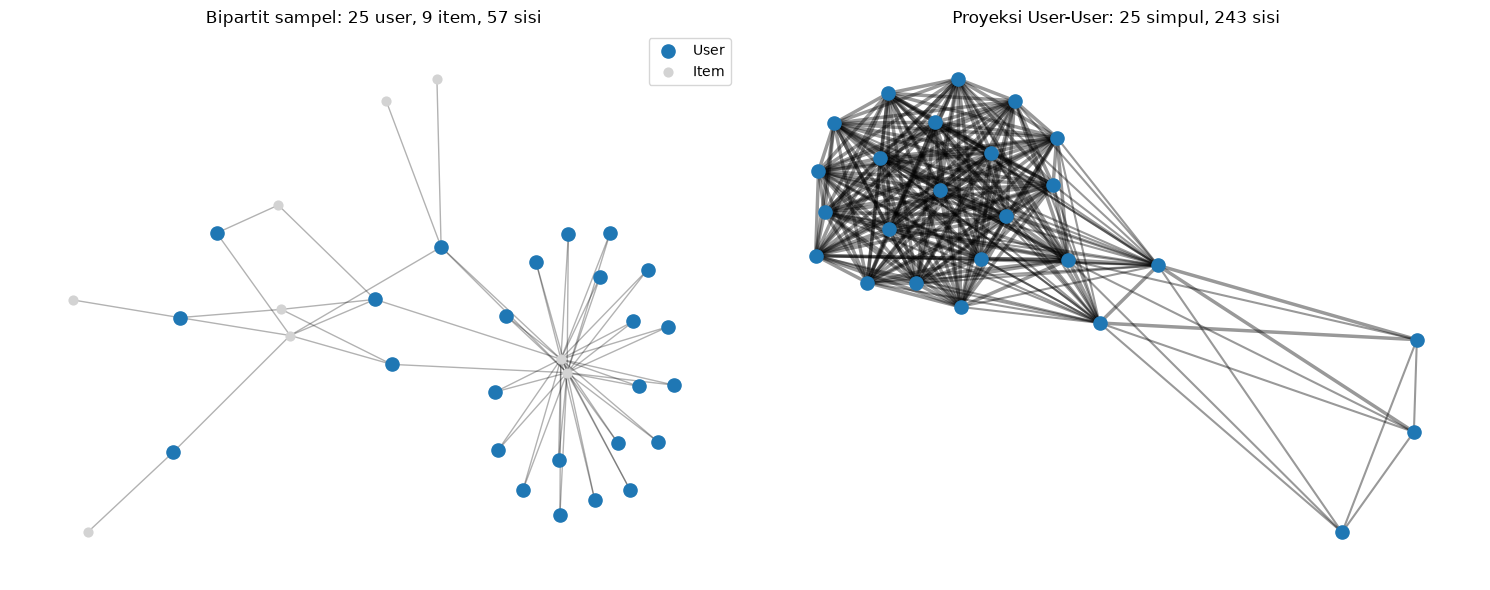

In [10]:
XU = X
n_user, n_item = XU.shape
deg_u = np.asarray(XU.sum(axis=1)).ravel()         

karakteristik_u = pd.DataFrame({
    "ukuran": ["shape (user x item)", "dimensi vektor (= jumlah item)", "jumlah vektor (= jumlah user)",
               "elemen nonzero", "density", "sparsity",
               "rata-rata item per user", "median", "persentil 90", "persentil 99", "maksimum",
               "user dengan hanya 1 item"],
    "nilai": [f"{n_user} x {n_item}", n_item, n_user, int(XU.nnz),
              f"{XU.nnz / (n_user * n_item):.2e}", f"{1 - XU.nnz / (n_user * n_item):.6f}",
              f"{deg_u.mean():.2f}", f"{np.median(deg_u):.0f}", f"{np.percentile(deg_u, 90):.0f}",
              f"{np.percentile(deg_u, 99):.0f}", f"{deg_u.max():.0f}",
              f"{(deg_u == 1).sum()} ({(deg_u == 1).mean():.2%})"],
})
display(karakteristik_u)

sub = sample_subgraph()
users_n = [f"U{u}" for u in sub.visitorid.unique()]
items_n = [f"I{i}" for i in sub.itemid.unique()]
B = nx.Graph()
B.add_nodes_from(users_n, bipartite=0); B.add_nodes_from(items_n, bipartite=1)
B.add_edges_from((f"U{u}", f"I{i}") for u, i in zip(sub.visitorid, sub.itemid))
PU = nx.bipartite.weighted_projected_graph(B, users_n)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pos = nx.spring_layout(B, seed=SEED)
nx.draw_networkx_nodes(B, pos, nodelist=users_n, node_color="tab:blue", node_size=90, ax=ax[0], label="User")
nx.draw_networkx_nodes(B, pos, nodelist=items_n, node_color="lightgray", node_size=40, ax=ax[0], label="Item")
nx.draw_networkx_edges(B, pos, alpha=0.3, ax=ax[0]); ax[0].legend()
ax[0].set_title(f"Bipartit sampel: {len(users_n)} user, {len(items_n)} item, {B.number_of_edges()} sisi")
pos_u = nx.spring_layout(PU, seed=SEED)
w = [PU[a][b]["weight"] for a, b in PU.edges()]
nx.draw_networkx_nodes(PU, pos_u, node_color="tab:blue", node_size=90, ax=ax[1])
nx.draw_networkx_edges(PU, pos_u, width=[0.5 + x for x in w], alpha=0.4, ax=ax[1])
ax[1].set_title(f"Proyeksi User-User: {PU.number_of_nodes()} simpul, {PU.number_of_edges()} sisi")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

### 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

,ukuran,nilai
0,shape (item x user),165655 x 627439
1,dimensi vektor (= jumlah user),627439
2,jumlah vektor (= jumlah item),165655
3,elemen nonzero,958183
4,density,9.22e-06
5,sparsity,0.999991
6,rata-rata user per item,5.78
7,median,2
8,persentil 90,12
9,persentil 99,61


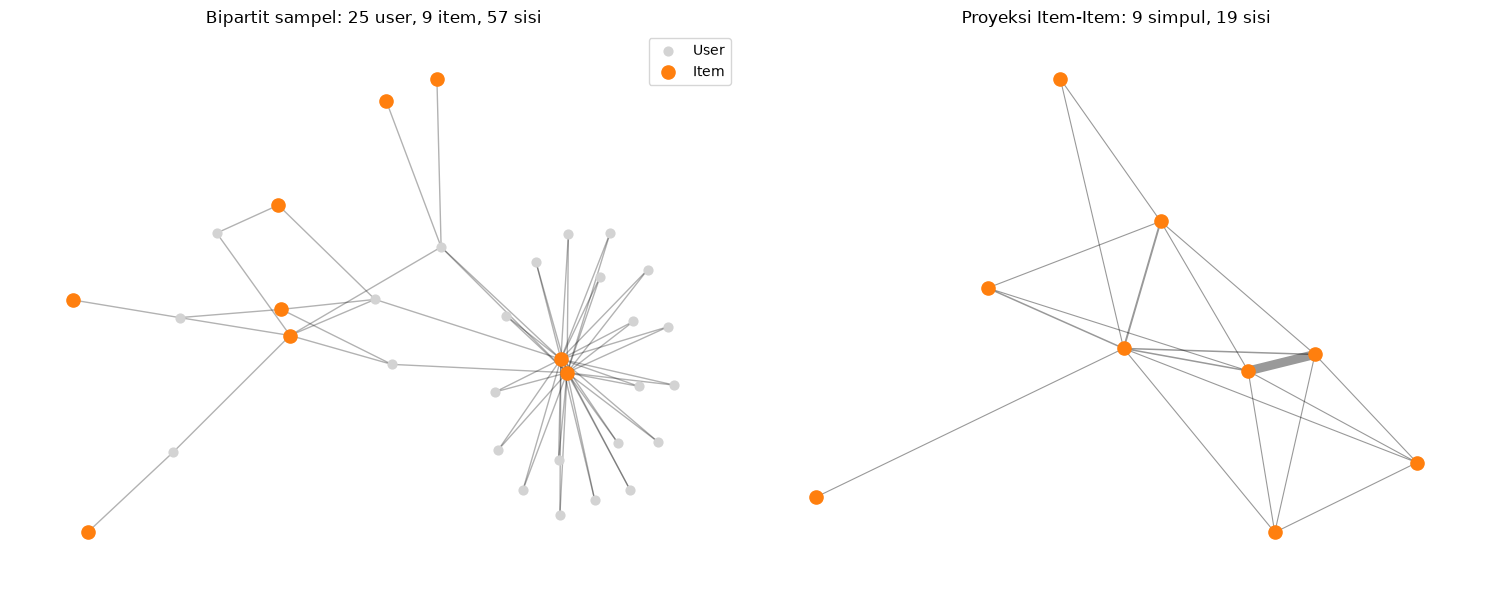

In [11]:
XI = X.T.tocsr()
n_item, n_user = XI.shape
deg_i = np.asarray(XI.sum(axis=1)).ravel()          

karakteristik_i = pd.DataFrame({
    "ukuran": ["shape (item x user)", "dimensi vektor (= jumlah user)", "jumlah vektor (= jumlah item)",
               "elemen nonzero", "density", "sparsity",
               "rata-rata user per item", "median", "persentil 90", "persentil 99", "maksimum",
               "item dengan hanya 1 user"],
    "nilai": [f"{n_item} x {n_user}", n_user, n_item, int(XI.nnz),
              f"{XI.nnz / (n_item * n_user):.2e}", f"{1 - XI.nnz / (n_item * n_user):.6f}",
              f"{deg_i.mean():.2f}", f"{np.median(deg_i):.0f}", f"{np.percentile(deg_i, 90):.0f}",
              f"{np.percentile(deg_i, 99):.0f}", f"{deg_i.max():.0f}",
              f"{(deg_i == 1).sum()} ({(deg_i == 1).mean():.2%})"],
})
display(karakteristik_i)

sub = sample_subgraph()
users_n = [f"U{u}" for u in sub.visitorid.unique()]
items_n = [f"I{i}" for i in sub.itemid.unique()]
B = nx.Graph()
B.add_nodes_from(users_n, bipartite=0); B.add_nodes_from(items_n, bipartite=1)
B.add_edges_from((f"U{u}", f"I{i}") for u, i in zip(sub.visitorid, sub.itemid))
PI = nx.bipartite.weighted_projected_graph(B, items_n)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pos = nx.spring_layout(B, seed=SEED)
nx.draw_networkx_nodes(B, pos, nodelist=users_n, node_color="lightgray", node_size=40, ax=ax[0], label="User")
nx.draw_networkx_nodes(B, pos, nodelist=items_n, node_color="tab:orange", node_size=90, ax=ax[0], label="Item")
nx.draw_networkx_edges(B, pos, alpha=0.3, ax=ax[0]); ax[0].legend()
ax[0].set_title(f"Bipartit sampel: {len(users_n)} user, {len(items_n)} item, {B.number_of_edges()} sisi")
pos_i = nx.spring_layout(PI, seed=SEED)
w = [PI[a][b]["weight"] for a, b in PI.edges()]
nx.draw_networkx_nodes(PI, pos_i, node_color="tab:orange", node_size=90, ax=ax[1])
nx.draw_networkx_edges(PI, pos_i, width=[0.5 + x * 0.3 for x in w], alpha=0.4, ax=ax[1])
ax[1].set_title(f"Proyeksi Item-Item: {PI.number_of_nodes()} simpul, {PI.number_of_edges()} sisi")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)! 
Perbandingan proyeksi User-User vs Item-Item

In [12]:
item_deg = np.asarray(X.sum(axis=0)).ravel()   # jumlah user per item
user_deg = np.asarray(X.sum(axis=1)).ravel()   # jumlah item per user
pairs_user_proj = (item_deg * (item_deg - 1) / 2).sum()   # pasangan user yang berbagi item (batas atas)
pairs_item_proj = (user_deg * (user_deg - 1) / 2).sum()   # pasangan item yang berbagi user (batas atas)
cmp = pd.DataFrame({
    "proyeksi": ["User-User", "Item-Item"],
    "jumlah simpul": [X.shape[0], X.shape[1]],
    "perkiraan sisi (batas atas)": [pairs_user_proj, pairs_item_proj],
    "rasio sisi/simpul": [pairs_user_proj / X.shape[0], pairs_item_proj / X.shape[1]],
})
display(cmp)

,proyeksi,jumlah simpul,perkiraan sisi (batas atas),rasio sisi/simpul
0,User-User,627439,21278870.0,33.913847
1,Item-Item,165655,10657920.0,64.338052


**Analisis**

1. **Ukuran graf.** Proyeksi Item-Item jauh lebih kecil: simpulnya hanya sekitar seperempat dari proyeksi User-User, dan jumlah sisinya hanya sekitar setengahnya (10,7 juta dibanding 21,3 juta). Karena biaya menghitung similarity dan kebutuhan memori berbanding lurus dengan jumlah sisi (pasangan simpul yang saling berhubungan), proyeksi Item-Item kira-kira dua kali lebih hemat.

2. **Kepadatan.** Proyeksi Item-Item lebih padat: setiap item rata-rata terhubung dengan sekitar 129 item lain, sedangkan setiap user hanya terhubung dengan sekitar 68 user lain. Kepadatannya 7,2 kali lebih tinggi. Artinya sebuah item memiliki lebih banyak "tetangga" yang berbagi pengunjung yang sama, sehingga informasi kemiripan per simpul lebih kaya. Sebaliknya, pada User-User banyak user yang hanya berbagi sedikit item dengan user lain, sehingga hubungannya lebih jarang.

3. **Penyebab perbedaan.** Banyaknya sisi pada proyeksi User-User berasal dari item populer: satu item yang dilihat oleh `d` user membentuk `d(d-1)/2` pasangan user. Sebaliknya, sisi pada proyeksi Item-Item berasal dari user yang berinteraksi dengan banyak item. Karena sebagian besar user hanya berinteraksi dengan sedikit item, pasangan item yang terbentuk lebih sedikit.

4. **Catatan batas atas.** Perkiraan sisi dihitung dengan Σ C(d, 2), sehingga dua simpul yang berbagi lebih dari satu tetangga dihitung lebih dari sekali. Jumlah sisi unik sebenarnya bisa lebih kecil, tetapi urutan perbandingannya (Item-Item lebih sedikit sisinya) kemungkinan besar tetap sama.

**Kesimpulan**

Proyeksi yang lebih baik dari sisi efisiensi adalah **Item-Item**, karena jumlah simpulnya jauh lebih sedikit (165.655 vs 627.439), jumlah sisinya sekitar setengahnya (10,7 juta vs 21,3 juta), dan strukturnya lebih padat sehingga lebih informatif per simpul. Proyeksi User-User lebih besar dan lebih jarang, sehingga lebih mahal untuk disimpan dan dihitung. Karena itu, perhitungan similarity pada No. 7 dilakukan pada proyeksi Item-Item.

### 7.  Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python (Item-Item)

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri 
record acuannya)! 

(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query
nya! 

In [13]:
with driver.session(database=DB) as s:
    s.run("MATCH ()-[r:SIMILAR_TO]->() DELETE r")

In [15]:
# Proyeksi Item-Item: bobot sisi = jumlah user bersama; similarity = cosine dari bobot tsb.
XT  = X.T.tocsr()                                  
deg = np.asarray(XT.sum(axis=1)).ravel()          
ref_row  = int(np.argmax(deg))                     
REF_ITEM = int(item_ids[ref_row])
print("Item acuan:", REF_ITEM, "| jumlah user:", int(deg[ref_row]))

shared = (XT @ XT[ref_row].T).toarray().ravel()    
cos = shared / np.sqrt(deg * deg[ref_row])         
cos[ref_row] = -1                                  
top5 = np.argsort(-cos, kind="stable")[:5]

top5_df = pd.DataFrame({
    "itemId": np.asarray(item_ids)[top5].astype(int),
    "shared_users": shared[top5].astype(int),
    "users_item": deg[top5].astype(int),
    "cosine": cos[top5],
})
display(top5_df)

Item acuan: 5411 | jumlah user: 1096


,itemId,shared_users,users_item,cosine
0,33030,53,114,0.149940
1,33956,18,37,0.089385
2,358234,18,43,0.082915
3,375492,22,127,0.058968
4,89143,11,35,0.056163


In [17]:
with driver.session(database=DB) as s:
    print("Item acuan ada :", s.run("MATCH (a:Item {itemId:$ref}) RETURN count(a) AS n", ref=REF_ITEM).single()["n"])
    print("SIMILAR_TO     :", s.run("MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n").single()["n"])

Item acuan ada : 1
SIMILAR_TO     : 0


**(a) Cypher untuk 5 item dengan similarity tertinggi**

In [20]:
Q7A = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
WITH a, collect(DISTINCT u) AS ua
UNWIND ua AS u
MATCH (u)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH a, size(ua) AS na, b, count(DISTINCT u) AS inter
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(ub:Visitor)
WITH a, na, b, inter, count(DISTINCT ub) AS nb
RETURN b.itemId AS itemId, inter AS shared_users, nb AS users_item,
       inter * 1.0 / sqrt(na * nb) AS cosine
ORDER BY cosine DESC LIMIT 5
"""
with driver.session(database=DB) as s:
    cy_df = pd.DataFrame(s.run(Q7A, ref=REF_ITEM).data())
display(cy_df)

,itemId,shared_users,users_item,cosine
0,33030,53,114,0.149940
1,33956,18,37,0.089385
2,358234,18,43,0.082915
3,375492,22,127,0.058968
4,89143,11,35,0.056163


**(b) Tulis kembali nilai similarity ke graf** sebagai relasi `SIMILAR_TO {score}`. 

In [21]:
COUNT_Q = "MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n"
with driver.session(database=DB) as s:
    before_n = s.run(COUNT_Q).single()["n"]

rows = [{"a": REF_ITEM, "b": int(b), "score": float(c)} for b, c in zip(top5_df.itemId, top5_df.cosine)]
WRITE_Q = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
"""
with driver.session(database=DB) as s:
    s.run(WRITE_Q, rows=rows)
    after_n = s.run(COUNT_Q).single()["n"]
    shown = s.run("""MATCH (a:Item {itemId:$ref})-[s:SIMILAR_TO]->(b:Item)
                     RETURN a.itemId AS dari, b.itemId AS ke, s.score AS score
                     ORDER BY score DESC""", ref=REF_ITEM).data()
print("SIMILAR_TO sebelum:", before_n, "| sesudah:", after_n)
display(pd.DataFrame(shown))

SIMILAR_TO sebelum: 0 | sesudah: 5


,dari,ke,score
0,5411,33030,0.149940
1,5411,33956,0.089385
2,5411,358234,0.082915
3,5411,375492,0.058968
4,5411,89143,0.056163


Perhitungan similarity dengan cypher
![Alt text](<perhitungan similarity.png>)

## 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity! 

Cypher yang digunakan:
```cypher
-- hapus similarity lama
MATCH ()-[r:SIMILAR_TO]->() DELETE r
-- hitung relasi SIMILAR_TO (sebelum = 0, sesudah = 5)
MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS jumlah_similar_to
-- struktur Visitor-Item di sekitar item acuan 
MATCH p=(v:Visitor)-[]->(i:Item {itemId: 5411}) RETURN p LIMIT 25
-- similarity yang ditambahkan 
MATCH p=(a:Item {itemId: 5411})-[:SIMILAR_TO]->(b:Item) RETURN p
```

Sebelum perhitungan similarity
![Alt text](<sebelum similarity.png>)

Sesudah perhitungan similarity
![Alt text](<sesudah similarity.png>)

Relasi SIMILAR_TO  sebelum: 0  |  sesudah: 5
Tetangga SIMILAR_TO item acuan sebelum: 0 | sesudah: 5


,ke_itemId,score
0,375492,0.058968
1,33956,0.089385
2,89143,0.056163
3,358234,0.082915
4,33030,0.149940


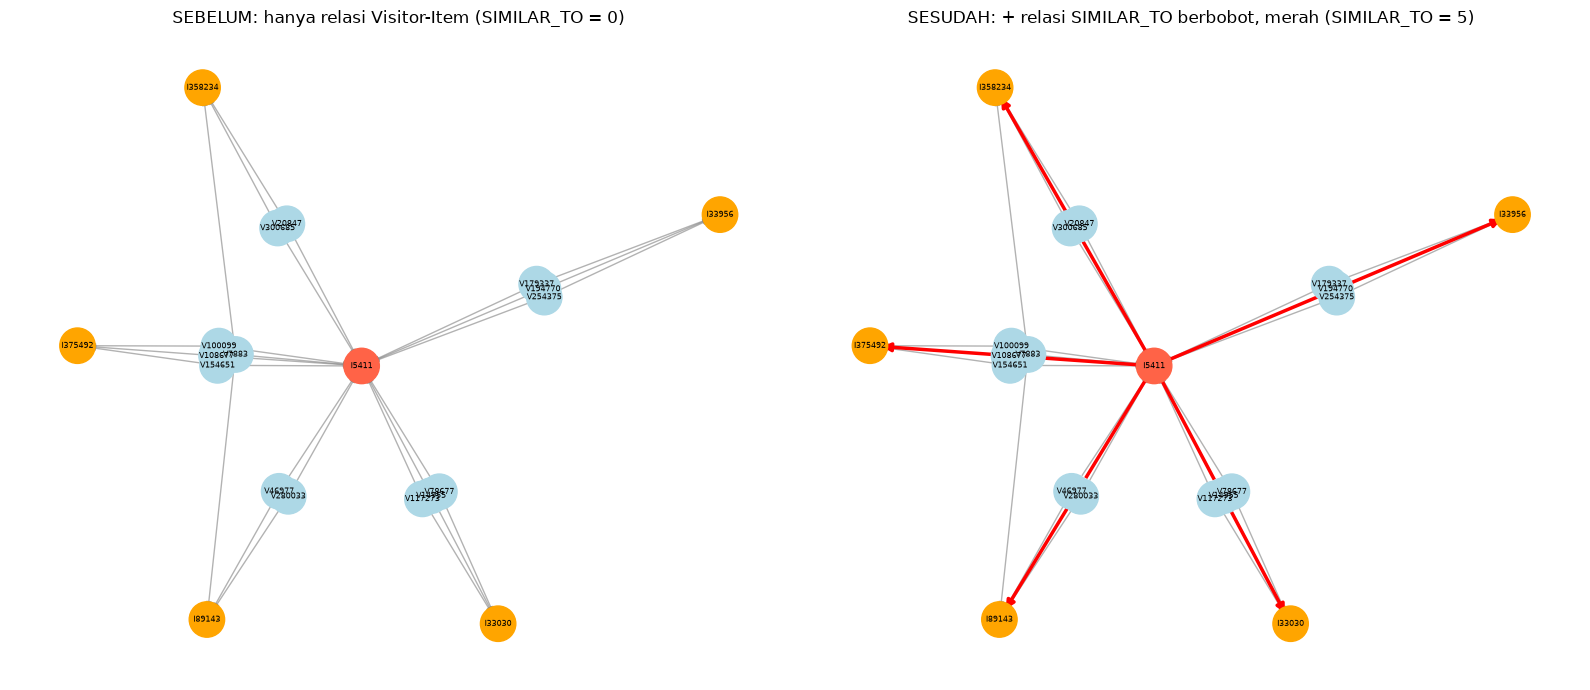

In [22]:
SIM_IDS = [int(i) for i in top5_df.itemId]
rows = [{"a": REF_ITEM, "b": int(b), "score": float(c)} for b, c in zip(top5_df.itemId, top5_df.cosine)]

Q_COUNT  = "MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n"
Q_DELETE = "MATCH ()-[r:SIMILAR_TO]->() DELETE r"
Q_STRUCT = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN $sim
WITH b.itemId AS b, v.visitorId AS vid
ORDER BY vid
WITH b, collect(DISTINCT vid)[..3] AS vs
UNWIND vs AS vid
RETURN b, vid AS v
"""
Q_AFTER = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS b, s.score AS score
"""
WRITE_Q = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
"""

with driver.session(database=DB) as s:
    # Sebelum
    s.run(Q_DELETE)
    n_before   = s.run(Q_COUNT).single()["n"]
    struct     = s.run(Q_STRUCT, ref=REF_ITEM, sim=SIM_IDS).data()
    aft_before = s.run(Q_AFTER, ref=REF_ITEM).data()
    
    # hasil perhitungan similarity ke graf
    s.run(WRITE_Q, rows=rows)
    
    # Sesudah
    n_after = s.run(Q_COUNT).single()["n"]
    aft     = s.run(Q_AFTER, ref=REF_ITEM).data()

print(f"Relasi SIMILAR_TO  sebelum: {n_before}  |  sesudah: {n_after}")
print("Tetangga SIMILAR_TO item acuan sebelum:", len(aft_before), "| sesudah:", len(aft))
display(pd.DataFrame(aft).rename(columns={"b": "ke_itemId"}))

# simpul yang sama pada kedua kondisi
ref_n = f"I{REF_ITEM}"
warna = {"ref": "tomato", "visitor": "lightblue", "item": "orange"}

def base_graph():
    G = nx.DiGraph()
    G.add_node(ref_n, kind="ref")
    for r in struct:
        v, b = f"V{r['v']}", f"I{r['b']}"
        G.add_node(v, kind="visitor"); G.add_node(b, kind="item")
        G.add_edge(v, ref_n); G.add_edge(v, b)
    return G

G_before = base_graph()
G_after  = base_graph()
for r in aft:
    G_after.add_edge(ref_n, f"I{r['b']}", score=r["score"])

pos = nx.spring_layout(G_after, seed=SEED)      

def gambar(G, ax, judul):
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=650,
                           node_color=[warna.get(G.nodes[n].get("kind"), "orange") for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    base_e = [(u, v) for u, v, d in G.edges(data=True) if "score" not in d]
    sim_e  = [(u, v, d["score"]) for u, v, d in G.edges(data=True) if "score" in d]
    nx.draw_networkx_edges(G, pos, edgelist=base_e, ax=ax, edge_color="gray", alpha=0.6, arrowsize=8)
    if sim_e:
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v) for u, v, _ in sim_e], ax=ax,
                               edge_color="red", width=2.5, arrowsize=12)
        nx.draw_networkx_edge_labels(G, pos, ax=ax, font_color="red", font_size=7,
                                     edge_labels={(u, v): f"{sc:.3f}" for u, v, sc in sim_e})
    ax.set_title(judul); ax.axis("off")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
gambar(G_before, ax[0], f"SEBELUM: hanya relasi Visitor-Item (SIMILAR_TO = {n_before})")
gambar(G_after,  ax[1], f"SESUDAH: + relasi SIMILAR_TO berbobot, merah (SIMILAR_TO = {n_after})")
plt.tight_layout(); plt.show()

**Kondisi sebelum.** Graf hanya memuat relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` antara simpul `Visitor` dan `Item`. Jumlah relasi `SIMILAR_TO` adalah **0**, dan item acuan belum memiliki tetangga `SIMILAR_TO` sama sekali. Hubungan antar-item baru dapat diketahui secara tidak langsung, yaitu melalui visitor yang sama-sama mengakses item tersebut.

**Perhitungan similarity.** Similarity dihitung pada proyeksi Item-Item menggunakan cosine biner, dengan item acuan 5411 (item dengan jumlah user terbanyak). Lima item dengan cosine tertinggi ditulis kembali ke graf sebagai relasi `SIMILAR_TO` dari item acuan ke masing-masing item tersebut, dengan nilai cosine disimpan pada properti `score`.

**Kondisi sesudah.** Jumlah relasi `SIMILAR_TO` berubah dari 0 menjadi 5.

Skor tertinggi adalah 0,1499 (item 33030) dan terendah 0,0562 (item 89143), dengan rata-rata sekitar 0,0875. Item 33030 jelas paling mirip dengan item acuan, karena skornya sekitar 1,7 kali skor peringkat kedua dan sekitar 2,7 kali skor peringkat kelima. Skor lainnya relatif berdekatan (0,056 sampai 0,089).

**Perbedaan graf sebelum dan sesudah.** Struktur Visitor-Item tidak berubah, baik simpul maupun relasinya. Yang bertambah hanyalah lima relasi berbobot antar-item (`SIMILAR_TO`). Dengan demikian, kemiripan item yang sebelumnya hanya bisa diturunkan dengan menelusuri visitor bersama, kini tersimpan langsung di graf dan dapat dibaca dengan satu langkah traversal, sehingga bisa dipakai untuk rekomendasi item.

## 2.2 Analytics

### 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu 
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya! 

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya! 

1a. Pilih user acak (reproducible) + KNN (user-based, cosine)

Proses acak: `random.Random(42).choice(kandidat)` dengan kandidat diurutkan terlebih dahulu. Kandidat = user yang ada di fold training (>= 3 item) dan punya minimal 1 item di fold testing yang juga ada di training (agar bisa dievaluasi)

In [23]:
te = pd.read_csv(os.path.join(DATA_DIR, "events_test.csv"), usecols=["visitorid", "itemid"]).drop_duplicates()
te = te[te.visitorid.isin(user_index) & te.itemid.isin(item_index)]
truth = te.groupby("visitorid").itemid.apply(set)

user_deg = np.asarray(X.sum(axis=1)).ravel()
cands = sorted(int(u) for u in truth.index if user_deg[user_index[u]] >= 3)
target = random.Random(SEED).choice(cands)
t_row = user_index[target]
print("Kandidat:", len(cands), "| user terpilih:", target, "| item training:", int(user_deg[t_row]), "| item testing (ground truth):", len(truth[target]))

item_pop = np.asarray(X.sum(axis=0)).ravel()       # popularitas item (untuk memecah skor yang sama)

def recommend_knn(u_row, k=5, n_rec=5):
    shared = (X @ X[u_row].T).toarray().ravel()            # jumlah item bersama dengan user target
    sims   = shared / np.sqrt(user_deg * user_deg[u_row])  # cosine biner
    baru   = user_deg - shared                             # item milik tetangga yang BELUM dikenal target
    layak  = (shared > 0) & (baru > 0)                     # tetangga harus mirip DAN punya item baru
    layak[u_row] = False
    sims_l = np.where(layak, sims, -1.0)
    nbrs = np.argsort(-sims_l, kind="stable")[:k]          # k tetangga terdekat (deterministik)
    nbrs = nbrs[sims_l[nbrs] > 0]
    scores = np.asarray(X[nbrs].T @ sims[nbrs]).ravel()    # skor item = jumlah similarity tetangga yang memilikinya
    scores[X[u_row].indices] = 0                           # jangan rekomendasikan item yang sudah dikenal user
    urut = np.lexsort((-item_pop, -scores))                # skor sama -> item lebih populer didahulukan
    order = [j for j in urut[:n_rec] if scores[j] > 0]
    return nbrs, sims[nbrs], [(int(item_ids[j]), float(scores[j])) for j in order]

nbrs, nbr_sims, recs = recommend_knn(t_row, k=5, n_rec=5)
print("Tetangga (k=5):")
for n, sm in zip(nbrs, nbr_sims):
    bersama = int(X[t_row].multiply(X[n]).sum())
    print(f"  user {int(user_ids[n])} | cosine={sm:.4f} | item={int(user_deg[n])} | bersama={bersama} | item baru={int(user_deg[n]) - bersama}")
print("Top-5 rekomendasi (item, skor):", recs)

Kandidat: 2608 | user terpilih: 234164 | item training: 63 | item testing (ground truth): 11
Tetangga (k=5):
  user 1019546 | cosine=0.1260 | item=4 | bersama=2 | item baru=2
  user 425707 | cosine=0.1260 | item=4 | bersama=2 | item baru=2
  user 925443 | cosine=0.1195 | item=10 | bersama=3 | item baru=7
  user 329500 | cosine=0.1127 | item=5 | bersama=2 | item baru=3
  user 383976 | cosine=0.1029 | item=6 | bersama=2 | item baru=4
Top-5 rekomendasi (item, skor): [(466350, 0.1259881576697424), (270144, 0.1259881576697424), (138266, 0.1259881576697424), (54910, 0.1259881576697424), (390379, 0.11952286093343938)]


1b. 3 item yang diiklankan (k = 5)

In [24]:
ads = recs[:3]
ads_df = pd.DataFrame(ads, columns=["itemId", "skor"])

def pendukung(item):
    j = item_index[item]
    return [int(user_ids[n]) for n in nbrs if X[n, j] > 0]    

ads_df["didukung_tetangga"] = ads_df["itemId"].map(pendukung)
print(f"3 item yang diiklankan untuk user {target} (k=5):", [i for i, _ in ads])
display(ads_df)

3 item yang diiklankan untuk user 234164 (k=5): [466350, 270144, 138266]


,itemId,skor,didukung_tetangga
0,466350,0.125988,[425707]
1,270144,0.125988,[1019546]
2,138266,0.125988,[1019546]


### 2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah: 

(a) Hit@5 

(b) NDCG@5 

Ground truth = item yang diakses user pada fold testing (yang ada di katalog training). Daftar yang dievaluasi = top-5 ranking (3 teratas adalah item iklan).

In [25]:
def hit_at_k(rec_items, truth_set, k=5):
      return int(any(i in truth_set for i in rec_items[:k]))

def ndcg_at_k(rec_items, truth_set, k=5):
      dcg  = sum(1.0 / np.log2(r + 2) for r, i in enumerate(rec_items[:k]) if i in truth_set)
      idcg = sum(1.0 / np.log2(r + 2) for r in range(min(len(truth_set), k)))
      return dcg / idcg if idcg > 0 else 0.0

rec_items = [i for i, _ in recs]
gt = {int(i) for i in truth[target]}
print("Hit@5  =", hit_at_k(rec_items, gt))
print("NDCG@5 =", round(ndcg_at_k(rec_items, gt), 4))

Hit@5  = 0
NDCG@5 = 0.0


Untuk user 234164 (63 item di training, 11 item ground truth di fold testing), top-5 rekomendasi (466350, 270144, 138266, 54910, 390379) tidak memiliki irisan dengan ground truth, sehingga Hit@5 = 0 dan NDCG@5 = 0. Hasil ini sah: katalog berisi 165.655 item, dan rekomendasi hanya bersumber dari 5 tetangga yang masing-masing berbagi 2-3 item dengan user target. Tiga item iklan masing-masing hanya didukung satu tetangga (cosine 0,126), sehingga sinyalnya lemah.

Karena satu user tidak representatif, evaluasi diperluas ke 200 user acak (seed 42), KNN memperoleh Hit@5 = 0,0200 dan NDCG@5 = 0,0065, sedangkan baseline popularitas 0,0000 untuk keduanya. Nilai absolut yang kecil wajar pada data yang sangat sparse (79,5% user hanya memiliki 1 item) dengan jeda 8 hari antara fold training dan testing.

In [26]:
gt_int = {int(i) for i in gt}
print("Jumlah ground truth       :", len(gt_int))
print("Irisan rekomendasi & truth:", set(rec_items) & gt_int)
print("Semua rekomendasi ada di katalog training:", all(i in item_index for i in rec_items))

Jumlah ground truth       : 11
Irisan rekomendasi & truth: set()
Semua rekomendasi ada di katalog training: True


In [27]:
from itertools import islice

pop_rank = np.argsort(-item_pop, kind="stable")          

def popular_top5(u_row):
    seen = set(X[u_row].indices)
    return [int(item_ids[j]) for j in islice((j for j in pop_rank if j not in seen), 5)]

sample_users = random.Random(SEED).sample(cands, min(200, len(cands)))
hasil = {"KNN (k=5)": ([], []), "Popularitas": ([], [])}

for u in tqdm(sample_users):
    r = user_index[u]
    gt_u = {int(i) for i in truth[u]}
    daftar = {
        "KNN (k=5)":   [i for i, _ in recommend_knn(r, k=5, n_rec=5)[2]],
        "Popularitas": popular_top5(r),
    }
    for nama, items in daftar.items():
        hasil[nama][0].append(hit_at_k(items, gt_u))
        hasil[nama][1].append(ndcg_at_k(items, gt_u))

for nama, (h, n) in hasil.items():
    print(f"{nama:12s} | Hit@5 = {np.mean(h):.4f} | NDCG@5 = {np.mean(n):.4f} | n = {len(h)} user")

  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:06<00:00, 29.68it/s]

KNN (k=5)    | Hit@5 = 0.0200 | NDCG@5 = 0.0065 | n = 200 user
Popularitas  | Hit@5 = 0.0000 | NDCG@5 = 0.0000 | n = 200 user
